# The scattering sampler on non-Gaussian dust

[`03_sampling_pysm_dust.ipynb`](03_sampling_pysm_dust.ipynb) ran the Gaussian sampler on data with non-Gaussian PySM dust. This notebook runs a second sampler on the same kind of data, one whose dust model is not Gaussian, and compares the two on **one data set**.

The two posteriors share everything except the dust term:

| Sampler | Dust term of the log-posterior | Dust parameters | Dust field update |
|---|---|---|---|
| Gaussian (`sample_gaussian_posterior`) | $-\tfrac12\left[g^\dagger C_g^{-1} g + \log\det C_g\right]$, with a power-law $C_g$ | 2 amplitudes, 2 knees | exact Gaussian draw |
| scattering (`sample_scattering_posterior`) | $-\dfrac{1}{2\sigma^2}\sum_i \left[\log S_i(g) - \log S_i^{\rm target}\right]^2$ | none | one HMC step |

$S_i(g)$ are the wavelet scattering coefficients of the dust's E and B maps (below), and $\sigma$ is the width of the loss.

**Read the results with these limits in mind. This is a first, exploratory version, not a validated method:**

- **The target is the truth.** $S^{\rm target}$ is computed from the true PySM dust field of this very simulation. A real analysis would not have it; the target would have to come from a dust model or from other data.
- **$\sigma$ is hand-chosen**, the same for every coefficient. It is not derived from how much the coefficients vary between dust realizations.
- **The frequency exponent $\beta_d$ is held at its true value in the scattering chains.** Sampling it makes the chain run away; the last section shows this and explains why.
- **One map, one chain per configuration.** A difference smaller than the posterior width cannot be seen here.

In [1]:
import contextlib
import io
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from cmb_lensing.mcmc_diagnostics import autocorrelation, integrated_autocorrelation_time
from cmb_lensing.chain_analysis import product_moments, product_pdf
from cmb_scattering.simulate_dust import PYSM_DUST, simulate_data
from cmb_scattering.likelihoods import (SCATTERING_NUM_ORIENTATIONS, SCATTERING_NUM_SCALES,
                                        log_scattering_coefficients)
from cmb_scattering.sampler import (DUST_FIELD_NAME, PARAM_BOUNDS, PARAM_ORDER,
                                    sample_gaussian_posterior, sample_scattering_posterior)

#importing cmb_lensing.chain_analysis switches matplotlib to the file-only Agg backend,
#so switch back to drawing figures in the notebook
%matplotlib inline

nside = 128
theta_pix = 20.0
uk_arcmin = 3.0
map_seed = 0
r_true = 0.03
frequency_exponent_true = 1.49

#one data set with PySM d9 dust; both samplers run on it
sim = simulate_data(nside, theta_pix, map_seed, r_true, frequency_exponent_true,
                    uk_arcmin = uk_arcmin, dust_model = PYSM_DUST)

#the target of the scattering posterior: the coefficients of the true dust field
target_log_scattering_coefficients = log_scattering_coefficients(sim["dust_field"])
print("log scattering coefficients shape = (E , B, coefficients) = ", target_log_scattering_coefficients.shape)

log scattering coefficients shape = (E , B, coefficients) =  (2, 180)


## What the scattering coefficients measure

The scattering transform ([Mallat 2012](https://arxiv.org/abs/1101.2286); computed here with [Kymatio](https://www.kymat.io/)) convolves a map with wavelets $\psi_{j,\theta}$ of scale $2^j$ pixels and orientation $\theta$, takes the modulus, and averages:

- **First order,** $S_1(j, \theta) = \langle |g \star \psi_{j,\theta}| \rangle$: how much structure the map has at each scale and orientation. This is close to a band power.
- **Second order,** $S_2 = \langle ||g \star \psi_{j_1,\theta_1}| \star \psi_{j_2,\theta_2}| \rangle$ with $j_2 > j_1$: how the small-scale structure is *clustered* on larger scales. A Gaussian field with the same power spectrum has different second-order coefficients, which is what makes them a probe of non-Gaussianity.

With 5 scales and 4 orientations there are 20 first-order and 160 second-order coefficients per map.

The figure compares the PySM dust with a field that has exactly the same power in every Fourier mode but random phases, i.e. a Gaussian-like field with the PySM spectrum.

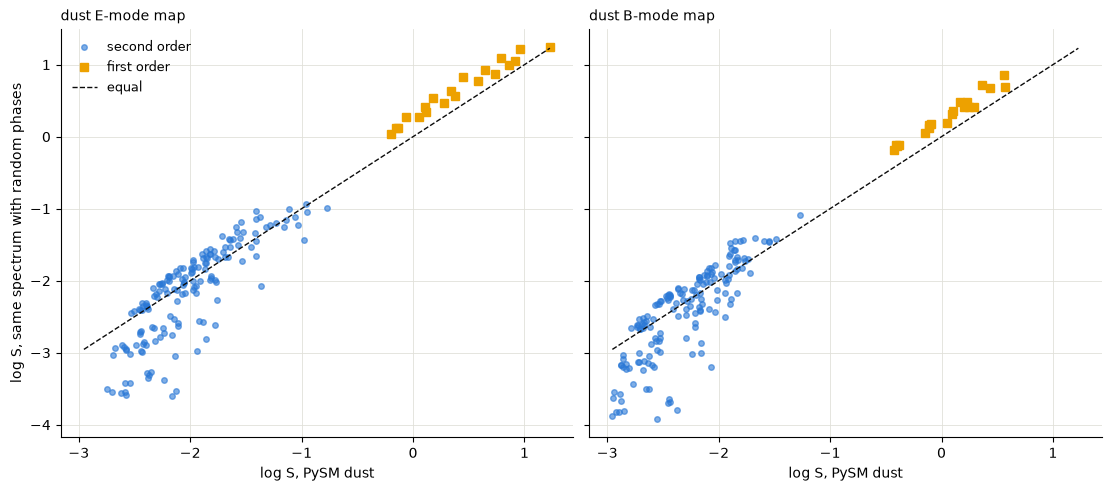

 first order: mean of log S(random phases) - log S(PySM) = +0.236, rms = 0.248
second order: mean of log S(random phases) - log S(PySM) = -0.134, rms = 0.415


In [2]:
INK = "#0b0b0b"
MUTED = "#898781"
GRID = "#e1e0d9"
GAUSSIAN_COLOR = "#2a78d6"
GAUSSIAN_FIXED_COLOR = "#1baf7a"
SCATTERING_COLOR = "#eb6834"
NO_PRIOR_COLOR = "#4a3aa7"
FIRST_ORDER_COLOR = "#eda100"
SECOND_ORDER_COLOR = "#2a78d6"
#seed of the random phases
PHASE_SEED = 5

num_first_order = SCATTERING_NUM_SCALES * SCATTERING_NUM_ORIENTATIONS

def style_axis(ax):
    ax.grid(color = GRID, lw = 0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

def randomize_phases(fourier_matrix, rng):
    #a field with the same |Fourier mode| everywhere and the phases of a white-noise map
    noise = np.fft.rfft2(rng.normal(size = (nside, nside)))
    phases = noise / np.abs(noise)
    return np.abs(np.asarray(fourier_matrix)) * phases

rng = np.random.default_rng(PHASE_SEED)
dust_field = sim["dust_field"]
random_phase_dust = dust_field.replace(
    polar_matrix_1 = randomize_phases(dust_field.polar_matrix_1, rng),
    polar_matrix_2 = randomize_phases(dust_field.polar_matrix_2, rng))
pysm_log_coefficients = np.asarray(target_log_scattering_coefficients)
random_phase_log_coefficients = np.asarray(log_scattering_coefficients(random_phase_dust))

fig, axes = plt.subplots(1, 2, figsize = (11, 4.8), sharex = True, sharey = True, constrained_layout = True)
for ax, mode, pysm_values, random_values in zip(axes, ("E", "B"), pysm_log_coefficients,
                                                random_phase_log_coefficients):
    ax.plot(pysm_values[num_first_order:], random_values[num_first_order:], "o", ms = 4,
            color = SECOND_ORDER_COLOR, alpha = 0.6, label = "second order")
    ax.plot(pysm_values[:num_first_order], random_values[:num_first_order], "s", ms = 6,
            color = FIRST_ORDER_COLOR, label = "first order")
    limits = [pysm_log_coefficients.min(), pysm_log_coefficients.max()]
    ax.plot(limits, limits, color = INK, lw = 1, ls = "--", label = "equal")
    ax.set_title(f"dust {mode}-mode map", loc = "left", fontsize = 10)
    ax.set_xlabel("log S, PySM dust")
    style_axis(ax)
axes[0].set_ylabel("log S, same spectrum with random phases")
axes[0].legend(frameon = False, fontsize = 9)
plt.show()

difference = random_phase_log_coefficients - pysm_log_coefficients
for label, columns in (("first order", slice(None, num_first_order)),
                       ("second order", slice(num_first_order, None))):
    print(f"{label:>12}: mean of log S(random phases) - log S(PySM) = {difference[:, columns].mean():+.3f}, "
          f"rms = {np.sqrt(np.mean(difference[:, columns]**2)):.3f}")

Points on the dashed line would mean the two fields have the same coefficient. They do not, even though the two fields have identical power spectra:

- **First order:** the random-phase field's coefficients are higher by 0.24 in the log on average, about 27 %. Both fields have the same mean *square* in each wavelet band, but the PySM dust concentrates its structure in a few bright regions, which gives a lower mean *modulus*.
- **Second order:** the random-phase field's coefficients are lower by 0.13 on average, and scatter about the PySM values with an rms of 0.42. The largest deficits are at the smallest coefficients.

So the coefficients do separate this dust from a Gaussian field with its spectrum, by several times the loss width $\sigma = 0.1$ used below.

## Running the samplers

In [3]:
num_iterations = 1500
chain_seed = 1
#iterations dropped from the start of each chain
burn_in = 200
#width of the L2 loss on each log scattering coefficient
scattering_width = 0.1
#a width so large that the scattering term vanishes: a control chain with no dust prior
NO_PRIOR_WIDTH = 1e6

#the Gaussian sampler's starting dust parameters: the power laws fitted to this dust in
#03_sampling_pysm_dust.ipynb
FITTED_DUST_PARAMS = {"dust_amplitude_ee": 28.87, "dust_knee_ee": -0.70,
                      "dust_amplitude_bb": 15.76, "dust_knee_bb": -0.63}
gaussian_param_init = dict(FITTED_DUST_PARAMS, r = r_true, frequency_exponent = frequency_exponent_true)
#proposal widths and knee bounds of the Gaussian sampler, as in 03_sampling_pysm_dust.ipynb
gaussian_proposal_widths = {
    "dust_amplitude_ee": 0.8,
    "dust_amplitude_bb": 0.4,
    "dust_knee_ee": 0.02,
    "dust_knee_bb": 0.02,
    "r": 0.008,
    "frequency_exponent": 0.002,
}
#a parameter left out of the proposal widths is not sampled and stays at its starting value
FIXED_PARAM = "frequency_exponent"
gaussian_fixed_proposal_widths = {name: width for name, width in gaussian_proposal_widths.items()
                                  if name != FIXED_PARAM}
scattering_fixed_proposal_widths = {"r": gaussian_proposal_widths["r"]}
WIDE_KNEE_BOUNDS = (-2.0, 0.0)
gaussian_param_bounds = dict(PARAM_BOUNDS, dust_knee_ee = WIDE_KNEE_BOUNDS, dust_knee_bb = WIDE_KNEE_BOUNDS)
scattering_param_init = {"r": r_true, "frequency_exponent": frequency_exponent_true}

model_arguments = (sim["data"], sim["noise_covariance"], sim["scalar_covariance"],
                   sim["tensor_covariance"], sim["mask"], sim["beam"])

def run_gaussian(proposal_widths):
    return sample_gaussian_posterior(*model_arguments, gaussian_param_init,
                                     proposal_widths = proposal_widths,
                                     param_bounds = gaussian_param_bounds,
                                     num_iterations = num_iterations, seed = chain_seed,
                                     frequencies = sim["frequencies"])

def run_scattering(width, proposal_widths, iterations):
    return sample_scattering_posterior(*model_arguments, scattering_param_init,
                                       target_log_scattering_coefficients,
                                       scattering_width = width, proposal_widths = proposal_widths,
                                       num_iterations = iterations, seed = chain_seed,
                                       frequencies = sim["frequencies"])

GAUSSIAN, GAUSSIAN_FIXED = "Gaussian", "Gaussian, beta fixed"
SCATTERING, NO_PRIOR = "scattering, beta fixed", "no dust prior, beta fixed"
colors = {GAUSSIAN: GAUSSIAN_COLOR, GAUSSIAN_FIXED: GAUSSIAN_FIXED_COLOR,
          SCATTERING: SCATTERING_COLOR, NO_PRIOR: NO_PRIOR_COLOR}
chains = {}
#capture the per-iteration acceptance printout
with contextlib.redirect_stdout(io.StringIO()):
    chains[GAUSSIAN] = run_gaussian(gaussian_proposal_widths)
    chains[GAUSSIAN_FIXED] = run_gaussian(gaussian_fixed_proposal_widths)
    chains[SCATTERING] = run_scattering(scattering_width, scattering_fixed_proposal_widths, num_iterations)
    chains[NO_PRIOR] = run_scattering(NO_PRIOR_WIDTH, scattering_fixed_proposal_widths, num_iterations)
sample_histories = {label: chain[0] for label, chain in chains.items()}
acceptance_rates = {label: chain[1] for label, chain in chains.items()}
logposterior_values = {label: chain[2] for label, chain in chains.items()}

print(f"{'acceptance rate':>20}  " + "  ".join(f"{label:>26}" for label in chains))
for name in PARAM_ORDER + [DUST_FIELD_NAME]:
    rates = [f"{acceptance_rates[label][name]:26.2f}" if name in acceptance_rates[label]
             else f"{'-':>26}" for label in chains]
    print(f"{name:>20}  " + "  ".join(rates))

     acceptance rate                    Gaussian        Gaussian, beta fixed      scattering, beta fixed   no dust prior, beta fixed
   dust_amplitude_ee                        0.53                        0.51                           -                           -
   dust_amplitude_bb                        0.53                        0.56                           -                           -
        dust_knee_ee                        0.40                        0.39                           -                           -
        dust_knee_bb                        0.38                        0.39                           -                           -
                   r                        0.47                        0.47                        0.44                        0.45
  frequency_exponent                        0.37                           -                           -                           -
          dust_field                           -                     

Four chains ran on the same data, all from the same sampler seed:

| Chain | Dust model | $\beta_d$ |
|---|---|---|
| Gaussian | power-law Gaussian prior | sampled, as in notebook 03 |
| Gaussian, beta fixed | power-law Gaussian prior | held at the truth |
| scattering, beta fixed | scattering loss, $\sigma = 0.1$ | held at the truth |
| no dust prior, beta fixed | scattering loss switched off ($\sigma = 10^6$) | held at the truth |

The second chain is the fair comparison for the third, since both know $\beta_d$. The fourth is a control: it is the scattering sampler with its dust term removed, so any difference between the third and the fourth is what the scattering term does.

A dash marks a parameter that chain does not sample. The dust field's rate is the acceptance rate of its HMC update; the Gaussian sampler draws its dust field exactly and has no such rate.

## Convergence

The log-posteriors of the different models are different functions, so only the shape of each curve matters, not its level.

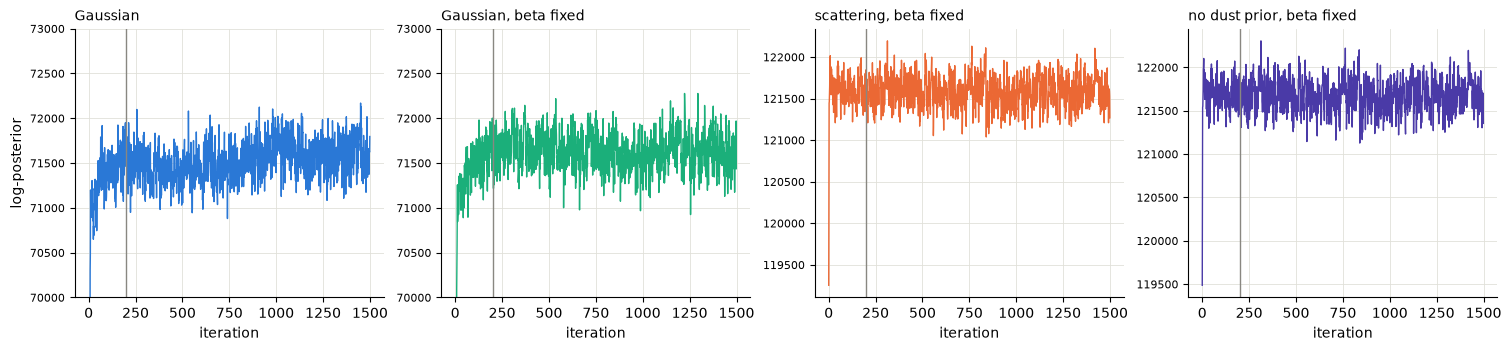

In [20]:
fig, axes = plt.subplots(1, len(chains), figsize = (15, 3.4), constrained_layout = True)
for ix, ax, label in zip(np.arange(len(axes)), axes, chains):
    ax.plot(logposterior_values[label], color = colors[label], lw = 1.0)
    ax.axvline(burn_in, color = MUTED, lw = 1)
    ax.set_title(label, loc = "left", fontsize = 10)
    ax.set_xlabel("iteration")
    ax.ticklabel_format(axis = "y", useOffset = False, style = "plain")
    ax.tick_params(axis = "y", labelsize = 8)
    if ix <2:
        ax.set_ylim(70_000, 73_000)
    style_axis(ax)
axes[0].set_ylabel("log-posterior")
plt.show()

## The recovered r

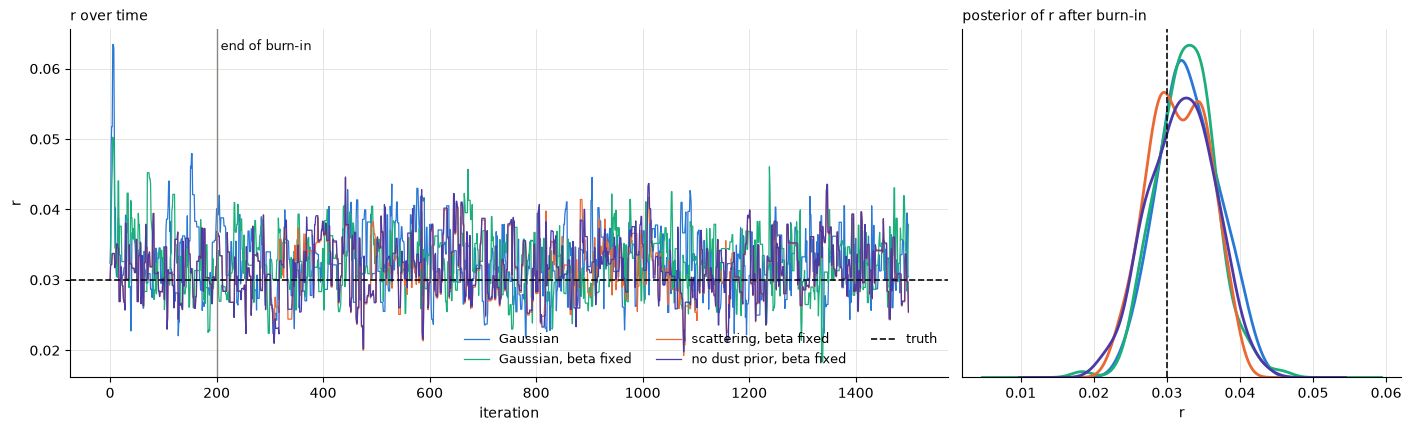

                     chain    mean r       std      bias   z-score     IAT  thinned samples
                  Gaussian    0.0331    0.0043   +0.0031     +0.71     9.0              163
      Gaussian, beta fixed    0.0326    0.0042   +0.0026     +0.61     8.5              163
    scattering, beta fixed    0.0316    0.0042   +0.0016     +0.39     8.6              163
 no dust prior, beta fixed    0.0321    0.0047   +0.0021     +0.44     9.5              145

scattering, beta fixed  minus  Gaussian, beta fixed: -0.0010 (-0.23 of the latter's std), width ratio 1.00
scattering, beta fixed  minus  no dust prior, beta fixed: -0.0004 (-0.09 of the latter's std), width ratio 0.90
Gaussian, beta fixed  minus  Gaussian: -0.0005 (-0.11 of the latter's std), width ratio 0.98

scattering and no-prior chains, sample by sample: rms difference in r 0.0016, correlation 0.92


In [21]:
KDE_GRID_POINTS = 400
#how far past the samples' range the density is drawn, as a fraction of that range
KDE_GRID_PADDING = 0.5

def chain_summary(chain, truth):
    #IAT, thinned samples, and the KDE's grid, density, mean and std for one parameter chain
    iat = integrated_autocorrelation_time(autocorrelation(chain))
    samples = chain[::max(int(iat), 1)]
    low, high = min(samples.min(), truth), max(samples.max(), truth)
    padding = KDE_GRID_PADDING * (high - low)
    grid = np.linspace(low - padding, high + padding, KDE_GRID_POINTS)
    density = product_pdf([gaussian_kde(samples)(grid)], grid)
    mean, std = product_moments(density, grid)
    return {"iat": iat, "num_samples": len(samples), "grid": grid, "density": density,
            "mean": mean, "std": std}

r_summary = {label: chain_summary(sample_histories[label]["r"][burn_in:], r_true) for label in chains}

fig, (trace_ax, density_ax) = plt.subplots(1, 2, figsize = (14, 4.2), width_ratios = (2, 1),
                                           constrained_layout = True)
for label in chains:
    trace_ax.plot(sample_histories[label]["r"], color = colors[label], lw = 0.9, label = label)
    density_ax.plot(r_summary[label]["grid"], r_summary[label]["density"], color = colors[label], lw = 2)
trace_ax.axhline(r_true, color = INK, lw = 1.2, ls = "--", label = "truth")
trace_ax.axvline(burn_in, color = MUTED, lw = 1)
trace_ax.text(burn_in, 0.97, " end of burn-in", color = INK, fontsize = 9, va = "top",
              transform = trace_ax.get_xaxis_transform())
trace_ax.set_xlabel("iteration")
trace_ax.set_ylabel("r")
trace_ax.set_title("r over time", loc = "left", fontsize = 10)
trace_ax.legend(frameon = False, fontsize = 9, ncols = 3, loc = "lower right")
density_ax.axvline(r_true, color = INK, lw = 1.2, ls = "--")
density_ax.set_xlabel("r")
density_ax.set_yticks([])
density_ax.set_ylim(bottom = 0)
density_ax.set_title("posterior of r after burn-in", loc = "left", fontsize = 10)
style_axis(trace_ax)
style_axis(density_ax)
plt.show()

print(f"{'chain':>26}  {'mean r':>8}  {'std':>8}  {'bias':>8}  {'z-score':>8}  {'IAT':>6}  {'thinned samples':>15}")
for label in chains:
    summary = r_summary[label]
    bias = summary["mean"] - r_true
    print(f"{label:>26}  {summary['mean']:8.4f}  {summary['std']:8.4f}  {bias:+8.4f}  "
          f"{bias / summary['std']:+8.2f}  {summary['iat']:6.1f}  {summary['num_samples']:15d}")

def print_shift(label_a, label_b):
    shift = r_summary[label_a]["mean"] - r_summary[label_b]["mean"]
    print(f"{label_a}  minus  {label_b}: {shift:+.4f} "
          f"({shift / r_summary[label_b]['std']:+.2f} of the latter's std), "
          f"width ratio {r_summary[label_a]['std'] / r_summary[label_b]['std']:.2f}")

print()
print_shift(SCATTERING, GAUSSIAN_FIXED)
print_shift(SCATTERING, NO_PRIOR)
print_shift(GAUSSIAN_FIXED, GAUSSIAN)

#the scattering and the control chain share their seed, so they can be compared sample by sample
sample_difference = sample_histories[SCATTERING]["r"] - sample_histories[NO_PRIOR]["r"]
print(f"\nscattering and no-prior chains, sample by sample: rms difference in r "
      f"{np.sqrt(np.mean(sample_difference[burn_in:]**2)):.4f}, correlation "
      f"{np.corrcoef(sample_histories[SCATTERING]['r'][burn_in:], sample_histories[NO_PRIOR]['r'][burn_in:])[0, 1]:.2f}")

The bias is the posterior mean minus the true $r = 0.03$, and the z-score is that bias in units of the posterior standard deviation.

**All four chains agree.** The means run from 0.0316 to 0.0331 with standard deviations of 0.0042 to 0.0047, so every chain is within 0.4 to 0.7 standard deviations of the truth and within 0.35 standard deviations of every other chain.

**The scattering term does almost nothing to $r$ on this data.** The scattering chain and the control with no dust prior share a seed, and their $r$ samples track each other iteration by iteration: correlation 0.92, mean shift $-0.0004$. The scattering chain's posterior is 10 % narrower, which is within what a KDE of about 150 thinned samples can resolve (roughly 6 % each), so it is not evidence of a tighter constraint.

**Holding $\beta_d$ fixed barely matters for the Gaussian sampler** either: its mean moves by $-0.0005$ and its width by 2 %.

## Why the frequency exponent is held fixed

The cell below runs the scattering sampler again with $\beta_d$ sampled, for fewer iterations.

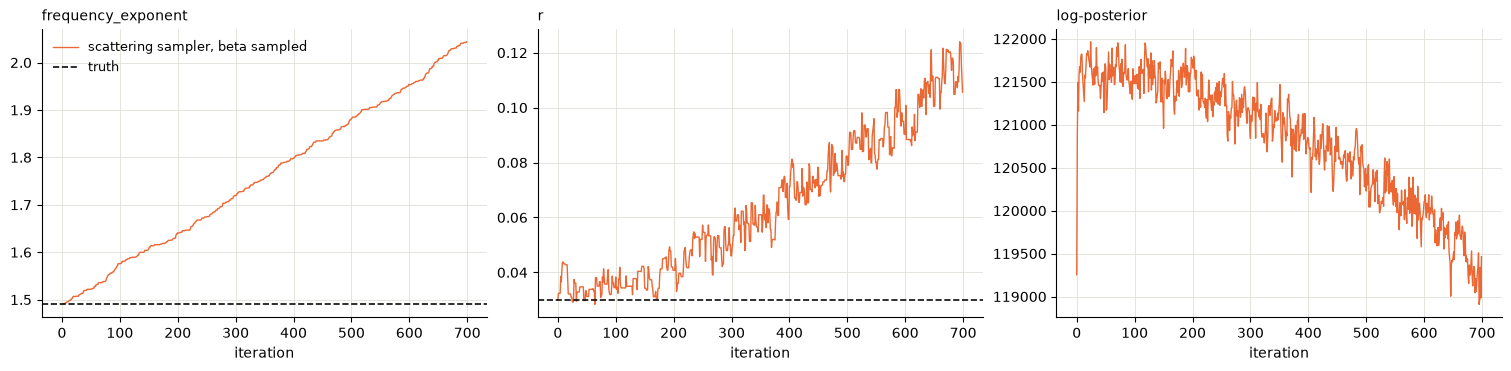

last 70 iterations: frequency_exponent = 2.016 (truth 1.49), r = 0.1115 (truth 0.03)
log-posterior, first 70 iterations: 121551, last 70: 119514


In [ ]:
#iterations of the chain that samples the frequency exponent
RUNAWAY_700 = 700
scattering_proposal_widths = {"r": gaussian_proposal_widths["r"],
                              "frequency_exponent": gaussian_proposal_widths["frequency_exponent"]}
with contextlib.redirect_stdout(io.StringIO()):
    runaway_histories, runaway_acceptance, runaway_logposterior = run_scattering(
        scattering_width, scattering_proposal_widths, RUNAWAY_700)

panels = (("frequency_exponent", runaway_histories["frequency_exponent"], frequency_exponent_true),
          ("r", runaway_histories["r"], r_true),
          ("log-posterior", runaway_logposterior, None))
fig, axes = plt.subplots(1, 3, figsize = (15, 3.6), constrained_layout = True)
for ax, (name, values, truth) in zip(axes, panels):
    ax.plot(values, color = SCATTERING_COLOR, lw = 1.0, label = "scattering sampler, beta sampled")
    if truth is not None:
        ax.axhline(truth, color = INK, lw = 1.2, ls = "--", label = "truth")
    ax.set_title(name, loc = "left", fontsize = 10)
    ax.set_xlabel("iteration")
    ax.ticklabel_format(axis = "y", useOffset = False, style = "plain")
    style_axis(ax)
axes[0].legend(frameon = False, fontsize = 9)
plt.show()

#the last tenth of the chain
tail = RUNAWAY_700 // 10
print(f"last {tail} iterations: frequency_exponent = {runaway_histories['frequency_exponent'][-tail:].mean():.3f} "
      f"(truth {frequency_exponent_true}), r = {runaway_histories['r'][-tail:].mean():.4f} (truth {r_true})")
print(f"log-posterior, first {tail} iterations: {runaway_logposterior[:tail].mean():.0f}, "
      f"last {tail}: {runaway_logposterior[-tail:].mean():.0f}")

**With $\beta_d$ sampled the chain does not converge.** In 700 iterations $\beta_d$ climbs steadily from 1.49 to about 2.0, far outside its prior of $1.49 \pm 0.13$, and drags $r$ from 0.03 to about 0.11. The log-posterior *falls* by about 2000 while this happens, so the chain is not climbing toward a better fit.

The likely reason is a volume effect, and it is a property of the posterior, not of the sampler. This explanation is consistent with the runs but has not been tested separately:

- The data pin down the product $a_\nu(\beta_d)\, g$, the dust as it appears in each channel. Raising $\beta_d$ lowers $a_\nu$, so the same data constrain $g$ itself more loosely: the range of dust fields compatible with the data grows by a factor for each of the 32,768 map pixels.
- A proper prior density on $g$ would penalize that. The Gaussian prior does: its $g^\dagger C_g^{-1} g$ and $\log\det C_g$ terms scale with the number of pixels.
- The scattering loss constrains only 360 numbers and has no normalization, so it cannot balance a gain that grows with the number of pixels. The chain drifts toward ever more volume, at a worse fit.

An earlier 2000-iteration run reached $\beta_d = 2.4$ at $\sigma = 0.1$ and $2.8$ at $\sigma = 0.5$, still rising in both.

## What this shows

1. **The scattering sampler runs and, with $\beta_d$ fixed, recovers $r$:** $0.0316 \pm 0.0042$ against a truth of 0.03, compared with $0.0326 \pm 0.0042$ for the Gaussian sampler with $\beta_d$ fixed. The two differ by 0.23 standard deviations.
2. **That agreement says little about the scattering term**, because a chain with no dust prior at all gives $0.0321 \pm 0.0047$. At 3 $\mu K$-arcmin in three channels the dust field is measured well by the data alone, and no dust prior, Gaussian or not, has much to add to $r$ on this map. This matches notebook 03, where swapping Gaussian dust for PySM dust did not move the Gaussian sampler's $r$.
3. **The scattering loss is not yet a usable dust prior.** It does not define a normalized density, and sampling $\beta_d$ with it runs away.

**What this does not show:** whether the scattering sampler is less biased than the Gaussian one. On one map both are within one standard deviation of the truth, and the data set is one where the dust model hardly matters. A test that could separate them needs a configuration where the dust prior matters (higher noise, fewer channels, or a frequency scaling the sampler does not know), a target that is not the truth, and many maps.

**Possible next steps:**

- Make the dust term a proper density, for example by keeping the Gaussian prior and adding the scattering loss to it, so that $\beta_d$ can be sampled.
- Find a configuration where the Gaussian sampler is visibly biased by PySM dust, and test the scattering term there.
- Set the loss width per coefficient from the spread between dust realizations.